# Ridge Regression

## 1. Objective

Evaluate whether L2 regularization improves predictive performance compared with the Linear Regression baseline.

Use the same training records, preprocessing specification, and five-fold cross-validation splits. Compare candidate alpha values using validation RMSE, with MAE and R² reported as additional metrics.

Keep preprocessing inside the pipeline so that imputation, scaling, and encoding are fitted separately within each training fold. Reserve the held-out test set for final evaluation.

## 2. Import Libraries

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import joblib

from sklearn.base import clone
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_predict

## 3. Load Training Data

### 3.1 Load Prepared Predictors and Target

Load the prepared training predictors and prices, preserving row indices and treating postcode as a categorical feature.

In [2]:
project_root = Path.cwd().parent

X_train = pd.read_csv(
    project_root / "data/processed/X_train.csv",
    index_col="row_index",
    dtype={"Postcode": str}
)

y_train = pd.read_csv(
    project_root / "data/processed/y_train.csv",
    index_col="row_index"
)["Price"]

print("Predictors:", X_train.shape)
print("Target:", y_train.shape)

Predictors: (10864, 16)
Target: (10864,)


### 3.2 Verify Training Data Alignment

Check that predictors and target have matching row indices, that row indices are unique, and that no target values are missing.

In [3]:
print("Rows aligned:", X_train.index.equals(y_train.index))
print(
    "Unique row indices:",
    X_train.index.is_unique and y_train.index.is_unique
)
print("Missing target values:", y_train.isna().sum())

Rows aligned: True
Unique row indices: True
Missing target values: 0


**Observation**

The training data contains 10,864 records and 16 predictors. Predictor and target indices match, row indices are unique, and the target contains no missing values.

### 3.3 Load the Unfitted Preprocessor

Load the preprocessing specification used for the Linear Regression baseline. Its imputation, scaling, and encoding steps will be fitted within each training fold during cross-validation.

In [4]:
preprocessor = joblib.load(
    project_root / "models/preprocessor_unfitted.joblib"
)

preprocessor

,transformers,"[('numerical', ...), ('categorical', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,missing_values,nan
,strategy,'median'
,fill_value,None


## 4. Cross-Validation Setup

### 4.1 Define Reproducible Folds

Use five shuffled folds with the same random seed and training row order as the Linear Regression baseline to reproduce its validation splits.

In [5]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_splits = list(cv.split(X_train, y_train))

print("Number of folds:", len(cv_splits))

Number of folds: 5


### 4.2 Define Evaluation Metrics

Evaluate Ridge using MAE, RMSE, and R². Select alpha using the lowest mean validation RMSE. Report MAE and R² as additional measures of predictive performance.

In [6]:
scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

## 5. Build the Ridge Pipeline

Combine a fresh copy of the preprocessor with Ridge Regression. During cross-validation, preprocessing and model fitting will use only the training portion of each fold.

In [7]:
ridge_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", Ridge(solver="lsqr"))
])

### 5.1 Define the Alpha Search Grid

Compare positive alpha values spanning weak to strong regularization. Select the best candidate using mean cross-validation RMSE. Review the search range if the best value lies at either boundary.

In [8]:
param_grid = {
    "model__alpha": [0.01, 0.1, 1, 10, 100, 1000]
}

### 5.2 Configure the Cross-Validation Search

Evaluate each alpha using the predefined folds and scoring metrics. Select the candidate with the lowest mean validation RMSE and refit its pipeline on the full training dataset.

In [9]:
ridge_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=param_grid,
    scoring=scoring,
    cv=cv_splits,
    refit="RMSE",
    return_train_score=True,
    error_score="raise"
)

### 5.3 Run the Ridge Search

Fit the search on the training data. Evaluate all candidate alpha values through cross-validation, then refit the selected pipeline on the full training set.

In [10]:
ridge_search.fit(X_train, y_train)

print("Ridge cross-validation search completed.")

Ridge cross-validation search completed.


## 6. Review Search Results

### 6.1 Inspect the Selected Alpha

Report the alpha with the lowest mean cross-validation RMSE. This score was used for model selection and is not a held-out test result.

In [11]:
print("Best alpha:", ridge_search.best_params_["model__alpha"])
print("Mean validation RMSE:", round(-ridge_search.best_score_, 2))

Best alpha: 10
Mean validation RMSE: 388385.43


**Observation**

Alpha 10 achieved the lowest mean validation RMSE (388,385.43) among the tested candidates. This is approximately 1.77% lower than the Linear Regression baseline. The selected alpha lies within the search range. This improvement reflects cross-validation used for alpha selection; held-out test performance remains unevaluated.

### 6.2 Compare Alpha Candidates

Review mean validation MAE, RMSE, and R² across all tested alpha values to examine how predictive performance changes with regularization strength.

In [12]:
cv_results = pd.DataFrame(ridge_search.cv_results_)

alpha_comparison = pd.DataFrame({
    "Alpha": cv_results["param_model__alpha"].astype(float),
    "MAE": -cv_results["mean_test_MAE"],
    "RMSE": -cv_results["mean_test_RMSE"],
    "R2": cv_results["mean_test_R2"]
}).sort_values("Alpha")

alpha_comparison.round(3)

,Alpha,MAE,RMSE,R2
0,0.01,242733.995,394695.401,0.619
1,0.10,242344.292,392676.463,0.623
2,1.00,240371.396,390055.106,0.628
3,10.00,237848.212,388385.431,0.631
4,100.00,243307.902,398536.443,0.610
5,1000.00,258296.478,428457.933,0.548


**Observation**

Validation errors decreased as alpha increased from 0.01 to 10. Alpha 10 produced the lowest MAE and RMSE and the highest R² among the tested candidates. Performance deteriorated at alpha 100 and 1000, indicating that stronger regularization was less effective within this search. Training scores will help assess whether this deterioration is consistent with underfitting.

### 6.3 Compare Training and Validation Performance

Compare mean training and validation metrics for the selected alpha to assess the generalization gap.

In [13]:
best = cv_results.iloc[ridge_search.best_index_]

ridge_train_valid = pd.DataFrame({
    "Training": [
        -best["mean_train_MAE"],
        -best["mean_train_RMSE"],
        best["mean_train_R2"]
    ],
    "Validation": [
        -best["mean_test_MAE"],
        -best["mean_test_RMSE"],
        best["mean_test_R2"]
    ]
}, index=["MAE", "RMSE", "R2"])

ridge_train_valid.round(3)

,Training,Validation
MAE,228689.590,237848.212
RMSE,354574.351,388385.431
R2,0.694,0.631


**Observation**

At alpha 10, mean training RMSE was 354,574 compared with validation RMSE of 388,385. Relative to Linear Regression, Ridge increased training error while reducing validation error and narrowing the RMSE gap from approximately 48,619 to 33,811. This is consistent with regularization trading some training fit for better validation performance. The result remains a cross-validation comparison used during alpha selection.

### 6.4 Inspect Fold-Level Validation Scores

Inspect validation MAE, RMSE, and R² for the selected alpha across the five folds. These scores come from the completed search; no additional fitting is required.

In [14]:
ridge_fold_scores = pd.DataFrame({
    "Fold": range(1, 6),
    "MAE": [-best[f"split{i}_test_MAE"] for i in range(5)],
    "RMSE": [-best[f"split{i}_test_RMSE"] for i in range(5)],
    "R2": [best[f"split{i}_test_R2"] for i in range(5)]
})

ridge_fold_scores.round(3)

,Fold,MAE,RMSE,R2
0,1,235338.003,339163.171,0.683
1,2,230082.017,330479.832,0.677
2,3,234280.721,379004.655,0.667
3,4,236281.460,468250.918,0.500
4,5,253258.858,425028.580,0.626


**Observation**

At alpha 10, Ridge reduced validation MAE in all five folds relative to Linear Regression. RMSE and R² improved in four folds, but fold 4 showed higher RMSE (468,251 versus 460,028) and lower R² (0.500 versus 0.517). Its lower MAE alongside higher RMSE indicates that improvement was not uniform across error measures. The mean performance gain therefore does not imply improvement in every fold.

### 6.5 Summarize Cross-Validation Performance

Report the mean and standard deviation of the selected alpha's validation metrics across the five folds. Standard deviation describes fold-to-fold variation, not a confidence interval.

In [15]:
ridge_summary = (
    ridge_fold_scores[["MAE", "RMSE", "R2"]]
    .agg(["mean", "std"])
    .T
)

ridge_summary.round(3)

,mean,std
MAE,237848.212,8934.269
RMSE,388385.431,58277.578
R2,0.631,0.076


**Observation**

Ridge achieved mean validation MAE of 237,848, RMSE of 388,385, and R² of 0.631. Compared with Linear Regression, MAE varied slightly less across folds, while RMSE and R² varied more. Regularization improved average validation performance but did not reduce fold-to-fold variation in every metric. These standard deviations describe score variability, not coefficient stability.

### 6.6 Save Ridge Search Results

Save the full cross-validation search results, alpha comparison, selected-alpha fold scores, metric summary, and training–validation comparison.

In [16]:
tables_dir = project_root / "results/tables"
tables_dir.mkdir(parents=True, exist_ok=True)

cv_results.to_csv(
    tables_dir / "ridge_search_results.csv", index=False
)

alpha_comparison.to_csv(
    tables_dir / "ridge_alpha_comparison.csv", index=False
)

ridge_fold_scores.to_csv(
    tables_dir / "ridge_cv_fold_scores.csv", index=False
)

ridge_summary.to_csv(
    tables_dir / "ridge_cv_summary.csv", index_label="Metric"
)

ridge_train_valid.to_csv(
    tables_dir / "ridge_train_validation_summary.csv",
    index_label="Metric"
)

## 7. Compare Ridge with Linear Regression

Compare mean validation metrics using the same training records and cross-validation splits. Ridge results reflect alpha selection on these folds and are not an independent final evaluation.

In [17]:
linear_summary = pd.read_csv(
    tables_dir / "linear_cv_summary.csv",
    index_col="Metric"
)

model_comparison = pd.DataFrame({
    "Linear Regression": linear_summary["mean"],
    "Ridge": ridge_summary["mean"]
}).T

model_comparison.round(3)

,MAE,RMSE,R2
Linear Regression,242395.379,395384.443,0.618
Ridge,237848.212,388385.431,0.631


**Observation**

Ridge with alpha 10 reduced mean validation MAE by approximately 1.88% and RMSE by 1.77% compared with Linear Regression. Mean R² increased from 0.618 to 0.631. These results indicate a modest improvement under the current cross-validation setup. Because alpha was selected using these folds, independent confirmation remains reserved for final held-out evaluation.

In [18]:
model_comparison.to_csv(
    tables_dir / "linear_vs_ridge_cv_comparison.csv",
    index_label="Model"
)

### 7.1 Training and Validation RMSE Across Alpha Values

Plot mean training and validation RMSE for each candidate alpha to examine the effect of regularization strength. Highlight the alpha selected by cross-validation.

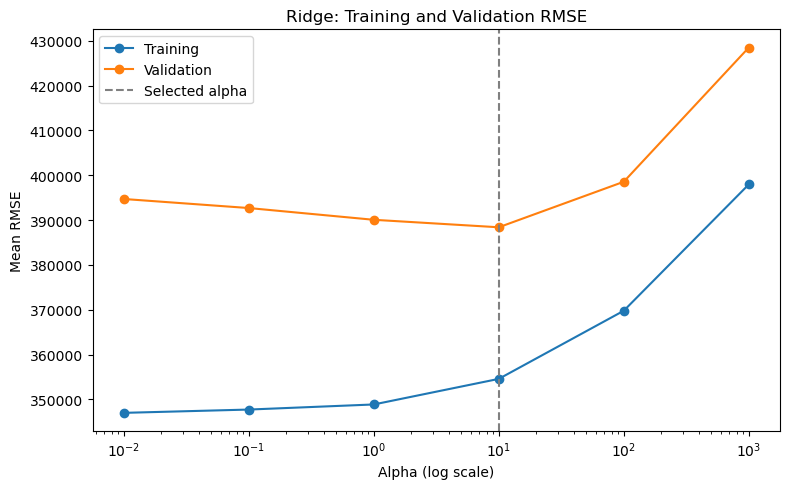

In [19]:
import matplotlib.pyplot as plt

alphas = cv_results["param_model__alpha"].astype(float)
train_rmse = -cv_results["mean_train_RMSE"]
valid_rmse = -cv_results["mean_test_RMSE"]

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(alphas, train_rmse, marker="o", label="Training")
ax.plot(alphas, valid_rmse, marker="o", label="Validation")

ax.axvline(
    ridge_search.best_params_["model__alpha"],
    color="grey",
    linestyle="--",
    label="Selected alpha"
)

ax.set_xscale("log")
ax.set_xlabel("Alpha (log scale)")
ax.set_ylabel("Mean RMSE")
ax.set_title("Ridge: Training and Validation RMSE")
ax.legend()

fig.tight_layout()

figures_dir = project_root / "results/figures"
figures_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figures_dir / "ridge_alpha_vs_rmse.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**Observation**

Training RMSE increased with regularization strength, while validation RMSE decreased up to alpha 10 before rising at alpha 100 and 1000. Alpha 10 provided the lowest mean validation RMSE among the tested candidates. The increase in both training and validation errors at larger alpha values is consistent with underfitting from excessive regularization. A smaller training–validation gap alone does not imply better predictive performance.

**Observation**

Training RMSE increased with regularization strength, while validation RMSE decreased up to alpha 10 before rising at alpha 100 and 1000. Alpha 10 provided the lowest mean validation RMSE among the tested candidates. The increase in both training and validation errors at larger alpha values is consistent with underfitting from excessive regularization. A smaller training–validation gap alone does not imply better predictive performance.

## 8. Inspect the Fitted Ridge Model

### 8.1 Retrieve the Selected Pipeline

Retrieve the pipeline refitted on the full training dataset after alpha selection. Use this fitted model for coefficient inspection. Its coefficients describe the full-training fit, whereas the reported validation scores came from separate fold-specific fits.

In [20]:
best_ridge_pipeline = ridge_search.best_estimator_

print(
    "Selected alpha:",
    best_ridge_pipeline.named_steps["model"].alpha
)

Selected alpha: 10


### 8.2 Extract Feature Coefficients

Match transformed feature names with coefficients from the fitted Ridge model. Numerical coefficients correspond to standardized inputs, while categorical coefficients correspond to encoded indicator columns.

In [21]:
feature_names = (
    best_ridge_pipeline.named_steps["preprocessor"]
    .get_feature_names_out()
)

ridge_coefficients = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": best_ridge_pipeline.named_steps["model"].coef_
})

print("Number of coefficients:", len(ridge_coefficients))
ridge_coefficients.head(10).round(3)

Number of coefficients: 802


,Feature,Coefficient
0,numerical__Rooms,163125.413
1,numerical__Distance,-194500.026
2,numerical__Bathroom,112585.871
3,numerical__Car,46341.554
4,numerical__Landsize,13814.644
5,numerical__BuildingArea,13135.395
6,numerical__YearBuilt,-48108.449
7,numerical__Lattitude,-92697.570
8,numerical__Longtitude,-8188.523
9,numerical__Propertycount,2261.269


**Observation**

The fitted Ridge model contains 802 coefficients: 10 for standardized numerical inputs and 792 for encoded categorical columns. Rooms and Bathroom have positive coefficients, while Distance has a negative coefficient. Numerical coefficients represent predicted price changes for a one-training-standard-deviation increase, holding other transformed inputs constant. They describe conditional model associations, not causal effects or a definitive ranking of feature importance.

### 8.3 Fit Linear Regression for Coefficient Comparison

Fit Linear Regression on the same full training data using an identical preprocessing specification. This fit is for coefficient comparison; predictive performance remains assessed using the previously reported cross-validation results.

In [22]:
linear_full_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", LinearRegression())
])

linear_full_pipeline.fit(X_train, y_train)

print("Linear Regression fitted for coefficient comparison.")

Linear Regression fitted for coefficient comparison.


### 8.4 Verify Feature Alignment

Confirm that both fitted pipelines produce identical transformed feature names in the same order before comparing coefficients.

In [23]:
linear_feature_names = (
    linear_full_pipeline.named_steps["preprocessor"]
    .get_feature_names_out()
)

same_features = pd.Index(linear_feature_names).equals(
    pd.Index(feature_names)
)

print("Same features and order:", same_features)

Same features and order: True


### 8.5 Compare Coefficient Magnitudes

Compare Linear Regression and Ridge coefficients for aligned transformed features. Measure shrinkage using absolute magnitudes so that positive and negative coefficients are treated consistently.

In [24]:
coefficient_comparison = pd.DataFrame({
    "Feature": feature_names,
    "Linear_Coefficient":
        linear_full_pipeline.named_steps["model"].coef_,
    "Ridge_Coefficient":
        best_ridge_pipeline.named_steps["model"].coef_
})

coefficient_comparison["Magnitude_Reduction"] = (
    coefficient_comparison["Linear_Coefficient"].abs()
    - coefficient_comparison["Ridge_Coefficient"].abs()
)

coefficient_comparison.head(10).round(3)

,Feature,Linear_Coefficient,Ridge_Coefficient,Magnitude_Reduction
0,numerical__Rooms,159254.656,163125.413,-3870.757
1,numerical__Distance,-233123.542,-194500.026,38623.515
2,numerical__Bathroom,104323.714,112585.871,-8262.157
3,numerical__Car,47612.970,46341.554,1271.415
4,numerical__Landsize,14027.045,13814.644,212.401
5,numerical__BuildingArea,159363.354,13135.395,146227.959
6,numerical__YearBuilt,-45412.270,-48108.449,-2696.178
7,numerical__Lattitude,-184415.897,-92697.570,91718.328
8,numerical__Longtitude,-86635.137,-8188.523,78446.615
9,numerical__Propertycount,35664.547,2261.269,33403.278


**Observation**

Among the ten numerical predictors, seven coefficient magnitudes decreased under Ridge, while Rooms, Bathroom, and YearBuilt increased. BuildingArea showed the largest absolute reduction, followed by Lattitude and Longtitude. This illustrates that Ridge does not shrink every individual coefficient uniformly. These changes describe the fitted models under the current preprocessing and encoding; they do not establish causal effects, feature irrelevance, or coefficient stability across training samples.

### 8.6 Compare Overall Coefficient Magnitudes

Calculate the L2 norm of all 802 coefficients for each fitted model, excluding the intercept. Compare overall magnitudes under the same preprocessing and encoding. This measures coefficient size, not predictive error or stability across training samples.

In [25]:
linear_norm = np.linalg.norm(
    coefficient_comparison["Linear_Coefficient"]
)

ridge_norm = np.linalg.norm(
    coefficient_comparison["Ridge_Coefficient"]
)

reduction_pct = (1 - ridge_norm / linear_norm) * 100

print("Linear Regression L2 norm:", round(linear_norm, 2))
print("Ridge L2 norm:", round(ridge_norm, 2))
print("L2 norm reduction (%):", round(reduction_pct, 2))

Linear Regression L2 norm: 12058067.48
Ridge L2 norm: 2104396.41
L2 norm reduction (%): 82.55


**Observation**

The coefficient L2 norm decreased from 12,058,067.48 for Linear Regression to 2,104,396.41 for Ridge, a reduction of 82.55%. This demonstrates substantial overall shrinkage under the current preprocessing and encoding, despite increases in some individual coefficients. The reduction is relative to the returned OLS solution, whose coefficients need not be unique under redundant encoding. It does not represent an equivalent reduction in prediction error or establish coefficient stability across training samples.

### 8.7 Save Coefficient Analysis Results

Save the fitted Ridge coefficients, the aligned Linear Regression comparison, and the overall L2 norm summary. These results describe models fitted on the full training dataset.

In [26]:
norm_summary = pd.DataFrame({
    "Linear_L2_Norm": [linear_norm],
    "Ridge_L2_Norm": [ridge_norm],
    "Reduction_Percentage": [reduction_pct]
})

ridge_coefficients.to_csv(
    tables_dir / "ridge_coefficients.csv",
    index=False
)

coefficient_comparison.to_csv(
    tables_dir / "linear_vs_ridge_coefficients.csv",
    index=False
)

norm_summary.to_csv(
    tables_dir / "ridge_coefficient_norm_summary.csv",
    index=False
)

## 9. OOF Prediction Diagnostics

### 9.1 Generate OOF Predictions at the Selected Alpha

Generate out-of-fold predictions using the selected alpha and the existing five folds. Each fold fits preprocessing and Ridge using only its training portion.

Because alpha was selected using these same folds, these predictions support exploratory diagnostics rather than independent evaluation of the tuning procedure.

In [27]:
ridge_oof_predictions = cross_val_predict(
    clone(best_ridge_pipeline),
    X_train,
    y_train,
    cv=cv_splits,
    method="predict"
)

print("OOF prediction shape:", ridge_oof_predictions.shape)

OOF prediction shape: (10864,)


### 9.2 Calculate Property-Level OOF Errors

Pair OOF predictions with actual prices using the original training row order. Calculate signed residuals and absolute errors for property-level diagnostics.

In [28]:
ridge_oof_results = pd.DataFrame({
    "Actual_Price": y_train,
    "Predicted_Price": ridge_oof_predictions
})

ridge_oof_results["Residual"] = (
    ridge_oof_results["Actual_Price"]
    - ridge_oof_results["Predicted_Price"]
)

ridge_oof_results["Absolute_Error"] = (
    ridge_oof_results["Residual"].abs()
)

ridge_oof_results.head().round(2)

,Actual_Price,Predicted_Price,Residual,Absolute_Error
row_index,,,,
12796,1480000.0,1610298.05,-130298.05,130298.05
9642,1530000.0,1168293.47,361706.53,361706.53
3207,690000.0,874209.88,-184209.88,184209.88
1698,570000.0,817187.38,-247187.38,247187.38
761,1041000.0,1503440.84,-462440.84,462440.84


**Observation**

The displayed OOF results contain both overprediction and underprediction. For example, property 12796 was overpredicted by 130,298, while property 9642 was underpredicted by 361,707. Absolute errors measure error magnitude without direction. These five records illustrate individual errors and do not establish an overall prediction bias.

**Observation**

The displayed OOF results contain both overprediction and underprediction. For example, property 12796 was overpredicted by 130,298, while property 9642 was underpredicted by 361,707. Absolute errors measure error magnitude without direction. These five records illustrate individual errors and do not establish an overall prediction bias.

In [29]:
ridge_oof_results[
    ["Residual", "Absolute_Error"]
].describe().round(2)

,Residual,Absolute_Error
count,10864.00,10864.00
mean,-1433.65,237846.79
std,391879.89,311441.17
min,-13867404.92,17.16
25%,-191738.11,76162.54
50%,-29983.33,169303.99
75%,140995.13,310408.45
max,8264861.14,13867404.92


**Observation**

Ridge produced a pooled OOF MAE of 237,847 and a median absolute error of 169,304. The much smaller mean signed residual (−1,434) reflects cancellation between overpredictions and underpredictions rather than small individual errors. Although average MAE improved relative to Linear Regression, the maximum absolute error increased from approximately 13.06 million to 13.87 million. Regularization therefore did not eliminate extreme prediction errors.

### 9.4 Inspect the Largest OOF Errors

Inspect the ten properties with the largest absolute OOF errors alongside their recorded features. This diagnostic review identifies cases requiring investigation; large errors alone do not justify removing records or establish their causes.

In [30]:
ridge_largest_errors = (
    ridge_oof_results
    .join(X_train[[
        "Suburb", "Type", "Rooms", "Distance",
        "Landsize", "BuildingArea", "YearBuilt"
    ]])
    .nlargest(10, "Absolute_Error")
)

ridge_largest_errors.round(2)

,Actual_Price,Predicted_Price,Residual,Absolute_Error,Suburb,Type,Rooms,Distance,Landsize,BuildingArea,YearBuilt
row_index,,,,,,,,,,,
13245,1355000.0,15222404.92,-13867404.92,13867404.92,New Gisborne,h,5,48.1,44500.0,44515.0,NaN
12094,9000000.0,735138.86,8264861.14,8264861.14,Mulgrave,h,3,18.8,744.0,117.0,1960.0
9575,7650000.0,2285185.44,5364814.56,5364814.56,Hawthorn,h,4,5.3,1690.0,284.0,1863.0
7692,8000000.0,3110570.63,4889429.37,4889429.37,Canterbury,h,5,9.0,2079.0,464.3,1880.0
6372,6250000.0,2207819.86,4042180.14,4042180.14,Toorak,h,3,4.6,564.0,342.0,2000.0
12557,6400000.0,2558186.23,3841813.77,3841813.77,Middle Park,h,5,3.0,553.0,308.0,1920.0
5631,5700000.0,1882907.34,3817092.66,3817092.66,South Yarra,h,4,3.3,292.0,272.0,1880.0
3114,5100000.0,1791200.19,3308799.81,3308799.81,Hawthorn,h,3,4.6,1038.0,NaN,NaN
3580,4800000.0,1605697.55,3194302.45,3194302.45,Kew,h,2,5.6,697.0,NaN,NaN


**Observation**

Property 13245 in New Gisborne remains the largest-error case, with a Ridge OOF prediction of 15.22 million against an actual price of 1.355 million. Its unusually large recorded land and building areas warrant investigation, but their contribution to the error cannot be established from this table alone. The other nine largest-error records are underpredicted high-priced houses. Ridge improved average validation performance but did not resolve these extreme cases. These selected records do not establish a pattern for all properties.

### 9.5 Actual vs OOF Predicted Prices

Plot all actual prices against Ridge OOF predictions. Use equal axis scales and an exact-prediction reference line to inspect agreement and extreme deviations. Predictions are diagnostic because alpha was selected using the same folds.

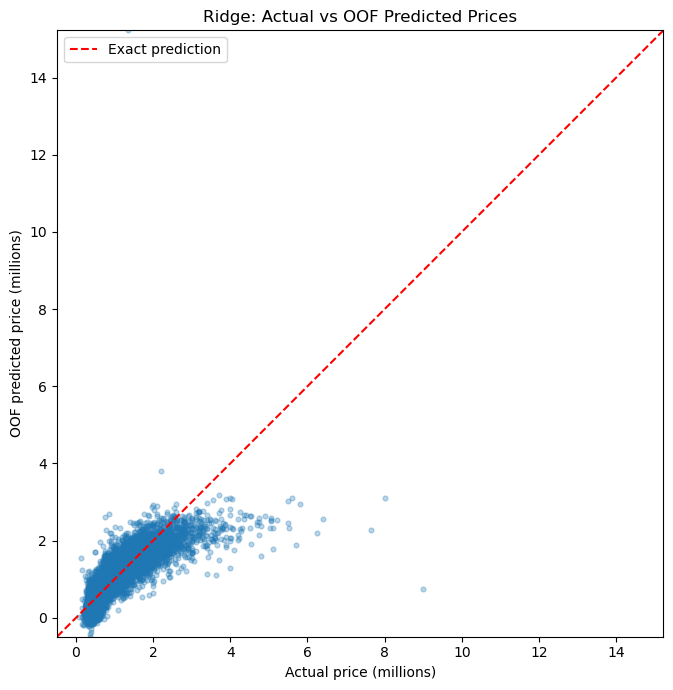

In [31]:
actual = ridge_oof_results["Actual_Price"] / 1_000_000
predicted = ridge_oof_results["Predicted_Price"] / 1_000_000

low = min(actual.min(), predicted.min())
high = max(actual.max(), predicted.max())

fig, ax = plt.subplots(figsize=(7, 7))

ax.scatter(actual, predicted, alpha=0.3, s=12)
ax.plot([low, high], [low, high], "r--", label="Exact prediction")

ax.set_xlabel("Actual price (millions)")
ax.set_ylabel("OOF predicted price (millions)")
ax.set_title("Ridge: Actual vs OOF Predicted Prices")
ax.set_xlim(low, high)
ax.set_ylim(low, high)
ax.set_aspect("equal", adjustable="box")
ax.legend()

fig.tight_layout()
fig.savefig(
    figures_dir / "ridge_oof_actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

**Observation**

OOF predictions generally increase with actual prices, but several high-priced properties lie substantially below the exact-prediction line, indicating underprediction. Some predictions are negative, which is implausible for property prices. Together with the extreme overprediction identified in the largest-error table, these results show that Ridge's modest average improvement did not resolve all prediction problems.

### 9.6 Residuals vs OOF Predicted Prices

Plot signed OOF residuals against predicted prices to examine systematic patterns, changes in error spread, and extreme deviations. Retain all records and use a horizontal zero-error reference line.

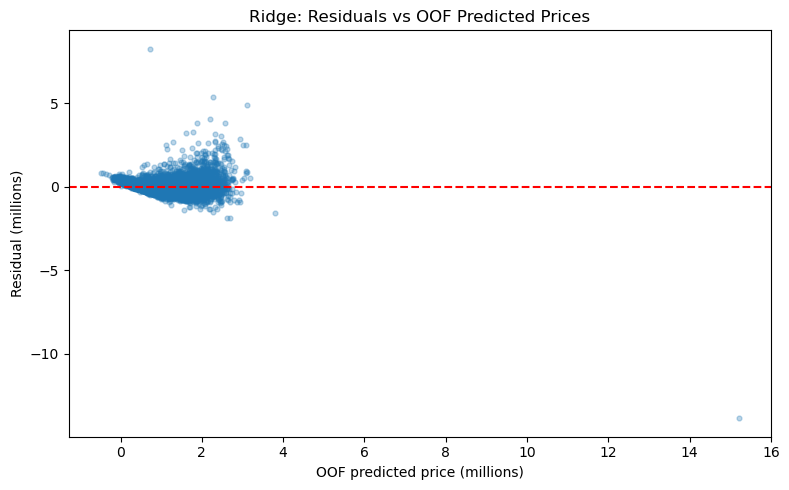

In [32]:
predicted = ridge_oof_results["Predicted_Price"] / 1_000_000
residuals = ridge_oof_results["Residual"] / 1_000_000

fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(predicted, residuals, alpha=0.3, s=12)
ax.axhline(0, color="red", linestyle="--")

ax.set_xlabel("OOF predicted price (millions)")
ax.set_ylabel("Residual (millions)")
ax.set_title("Ridge: Residuals vs OOF Predicted Prices")

fig.tight_layout()
fig.savefig(
    figures_dir / "ridge_oof_residuals_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

**Observation**

Within the main cluster, residual spread appears to increase with predicted price, suggesting non-constant error variance. Large deviations remain in both directions, including the New Gisborne overprediction of approximately 13.87 million and the Mulgrave underprediction of 8.26 million. These extreme cases compress the central pattern at this scale. Ridge's improved average validation performance therefore coexists with uneven error spread and substantial individual errors.

### 9.7 Summarize OOF Errors by Property Type

Summarize Ridge OOF errors separately for houses, townhouses, and units. Include group sizes and median prices to provide context for differences in absolute errors.

In [33]:
ridge_oof_by_type = ridge_oof_results.join(X_train["Type"])

ridge_type_error_summary = ridge_oof_by_type.groupby("Type").agg(
    Property_Count=("Absolute_Error", "size"),
    Median_Price=("Actual_Price", "median"),
    MAE=("Absolute_Error", "mean"),
    Median_Absolute_Error=("Absolute_Error", "median"),
    Mean_Residual=("Residual", "mean")
)

ridge_type_error_summary.round(2)

,Property_Count,Median_Price,MAE,Median_Absolute_Error,Mean_Residual
Type,,,,,
h,7532,1080000.0,253258.33,174119.52,-1745.59
t,903,860000.0,190832.48,153783.44,340.34
u,2429,560000.0,207535.64,164279.33,-1125.85


**Observation**

Ridge reduced OOF MAE across all three property types relative to Linear Regression, with the largest absolute reduction for units (7,791). Median absolute error decreased for houses and units but increased for townhouses from 148,330 to 153,783. Improvements therefore differ across error measures. Mean residuals remain small relative to MAE, indicating limited net signed bias despite substantial individual errors. These comparisons are diagnostic because alpha was selected using the same folds.

### 9.8 Save OOF Diagnostic Results

Save property-level OOF predictions and errors, the largest-error records, and the property-type summary. Preserve row indices to allow alignment with original records and other models' predictions.

In [34]:
ridge_oof_results.to_csv(
    tables_dir / "ridge_oof_predictions_and_errors.csv",
    index_label="row_index"
)

ridge_largest_errors.to_csv(
    tables_dir / "ridge_oof_largest_errors.csv",
    index_label="row_index"
)

ridge_type_error_summary.to_csv(
    tables_dir / "ridge_oof_errors_by_type.csv",
    index_label="Type"
)

## 10. Save the Fitted Ridge Pipeline

Save the selected pipeline refitted on the full training dataset. The artifact includes learned preprocessing and Ridge parameters. It expects the same 16 prepared predictor columns used during training; earlier cleaning and feature-preparation rules must be applied separately.

This is a candidate model artifact, not a model selected through final held-out evaluation.

In [35]:
models_dir = project_root / "models"
models_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(
    best_ridge_pipeline,
    models_dir / "ridge_pipeline_fitted.joblib"
)

['C:\\Users\\mamona\\Desktop\\house-price-linear-models\\models\\ridge_pipeline_fitted.joblib']

### 10.1 Verify the Saved Pipeline

Reload the saved Ridge pipeline and confirm that its predictions match the original fitted pipeline on the same sample of prepared training inputs.

In [36]:
loaded_ridge = joblib.load(
    models_dir / "ridge_pipeline_fitted.joblib"
)

sample = X_train.head()

print(
    "Predictions match:",
    np.allclose(
        best_ridge_pipeline.predict(sample),
        loaded_ridge.predict(sample)
    )
)

Predictions match: True


## 11. Overall Findings and Limitations

Ridge achieved its lowest mean validation RMSE at alpha = 10 among the six tested values. Compared with Linear Regression, mean validation MAE decreased from 242,395 to 237,848, RMSE decreased from 395,384 to 388,385, and R² increased from 0.618 to 0.631. These results indicate a modest improvement under the same cross-validation splits.

The full-training Ridge coefficient vector had an 82.55% lower L2 norm than the fitted Linear Regression vector. This demonstrates overall shrinkage, although some individual coefficients increased in magnitude. Coefficient shrinkage alone does not establish feature importance or stability.

OOF diagnostics showed that substantial errors remain. Several expensive properties were underpredicted, while the largest overprediction involved an unusually large recorded building area. Ridge reduced MAE across all three property types, but it did not improve every prediction or every error measure.

Alpha selection and subsequent OOF diagnostics used the same cross-validation splits. These are development results rather than an independent evaluation of the tuning procedure. The held-out test set remains unused and is reserved for final evaluation after model selection.

The fitted Ridge pipeline was saved and successfully reloaded, with matching predictions on a sample of prepared training inputs.